In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [2]:
df = pd.read_csv("../data/processed/telco_clean.csv")
print(df.shape)
df.head()

(7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [3]:
service_cols = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

df["num_services"] = (df[service_cols] == "Yes").sum(axis=1)
df["avg_monthly_spend"] = df["TotalCharges"] / (df["tenure"] + 1)
df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                            labels=["0-12", "13-24", "25-48", "49-72"]).astype(str)

df[["num_services", "avg_monthly_spend", "tenure_group"]].head()

,num_services,avg_monthly_spend,tenure_group
0,1,14.925000,0-12
1,3,53.985714,25-48
2,3,36.050000,0-12
3,3,40.016304,25-48
4,1,50.550000,0-12


In [4]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(X_train.shape, X_test.shape)
print(y_train.mean().round(3), y_test.mean().round(3))

(5634, 22) (1409, 22)
0.265 0.265


In [5]:
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
print("Numeric:", num_cols)
print("Categorical:", cat_cols)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

Numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'num_services', 'avg_monthly_spend']
Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'tenure_group']


In [6]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
    "XGBoost": XGBClassifier(eval_metric="logloss", random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["roc_auc", "recall", "precision", "f1"]

results = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    results.append({
        "model": name,
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "Recall": scores["test_recall"].mean(),
        "Precision": scores["test_precision"].mean(),
        "F1": scores["test_f1"].mean(),
    })

results_df = pd.DataFrame(results).set_index("model").round(3)
results_df

,ROC-AUC,Recall,Precision,F1
model,,,,
Logistic Regression,0.848,0.796,0.522,0.630
Random Forest,0.827,0.651,0.570,0.608
XGBoost,0.824,0.526,0.630,0.573


a simple model matched or beat complex ones.

In [7]:
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV

# Tell XGBoost that churners are the minority
ratio = (y_train == 0).sum() / (y_train == 1).sum()

xgb_pipe = Pipeline([("prep", preprocessor),
                     ("model", XGBClassifier(eval_metric="logloss", scale_pos_weight=ratio, random_state=42))])

xgb_params = {
    "model__n_estimators": [100, 200, 400],
    "model__max_depth": [2, 3, 4, 5],
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__subsample": [0.7, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.9, 1.0],
}

xgb_search = RandomizedSearchCV(xgb_pipe, xgb_params, n_iter=20, cv=cv,
                                scoring="roc_auc", n_jobs=-1, random_state=42)
xgb_search.fit(X_train, y_train)
print("XGBoost best CV ROC-AUC:", round(xgb_search.best_score_, 3))
print(xgb_search.best_params_)

lr_pipe = Pipeline([("prep", preprocessor),
                    ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))])

lr_search = GridSearchCV(lr_pipe, {"model__C": [0.01, 0.1, 1, 10]},
                         cv=cv, scoring="roc_auc", n_jobs=-1)
lr_search.fit(X_train, y_train)
print("Logistic Regression best CV ROC-AUC:", round(lr_search.best_score_, 3))
print(lr_search.best_params_)

XGBoost best CV ROC-AUC: 0.85
{'model__subsample': 0.7, 'model__n_estimators': 100, 'model__max_depth': 2, 'model__learning_rate': 0.1, 'model__colsample_bytree': 0.9}
Logistic Regression best CV ROC-AUC: 0.848
{'model__C': 10}


In [8]:
if xgb_search.best_score_ > lr_search.best_score_:
    final_model, final_name = xgb_search.best_estimator_, "XGBoost"
else:
    final_model, final_name = lr_search.best_estimator_, "Logistic Regression"

print("Final model:", final_name)

Final model: XGBoost


 threshold  recall  precision  net_value
      0.10   0.984      0.346     8300.0
      0.15   0.969      0.372    22750.0
      0.20   0.951      0.392    32100.0
      0.25   0.931      0.415    41000.0
      0.30   0.915      0.436    48350.0
      0.35   0.888      0.451    52000.0
      0.40   0.870      0.478    59150.0
      0.45   0.840      0.497    61950.0
      0.50   0.813      0.519    65300.0
      0.55   0.775      0.549    68150.0
      0.60   0.718      0.578    68100.0
      0.65   0.656      0.605    66050.0
      0.70   0.588      0.647    63950.0
      0.75   0.493      0.679    56250.0
      0.80   0.376      0.719    45200.0
      0.85   0.253      0.781    32500.0
      0.90   0.121      0.887    16950.0
Best threshold by net value: 0.55


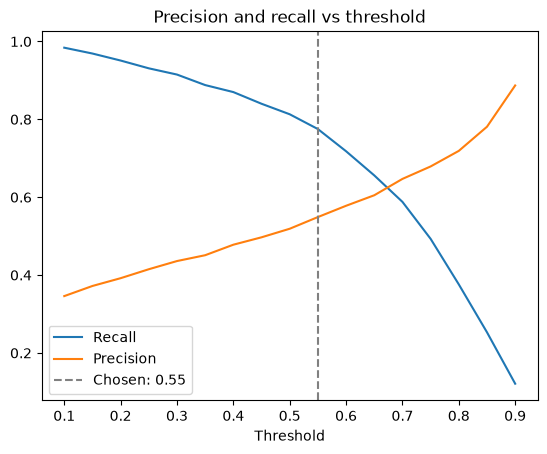

In [9]:
from sklearn.model_selection import cross_val_predict

# Out-of-fold probabilities on the TRAINING data only (the test set stays untouched)
proba = cross_val_predict(final_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

# Business assumptions: CHANGE THESE to whatever you want to defend
CUSTOMER_VALUE = 500      # what losing a customer costs
OFFER_COST = 50           # cost of a retention offer
SUCCESS_RATE = 0.30       # share of offers that keep the customer

thresholds = np.arange(0.10, 0.91, 0.05)
rows = []
for t in thresholds:
    pred = (proba >= t).astype(int)
    tp = ((pred == 1) & (y_train == 1)).sum()
    fp = ((pred == 1) & (y_train == 0)).sum()
    fn = ((pred == 0) & (y_train == 1)).sum()
    recall = tp / (tp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    net = tp * (SUCCESS_RATE * CUSTOMER_VALUE - OFFER_COST) - fp * OFFER_COST
    rows.append({"threshold": round(t, 2), "recall": recall, "precision": precision, "net_value": net})

th_df = pd.DataFrame(rows).round(3)
print(th_df.to_string(index=False))

best_t = th_df.loc[th_df["net_value"].idxmax(), "threshold"]
print("Best threshold by net value:", best_t)

plt.plot(th_df["threshold"], th_df["recall"], label="Recall")
plt.plot(th_df["threshold"], th_df["precision"], label="Precision")
plt.axvline(best_t, color="gray", linestyle="--", label=f"Chosen: {best_t}")
plt.xlabel("Threshold"); plt.legend(); plt.title("Precision and recall vs threshold")
plt.show()

Test ROC-AUC: 0.847
              precision    recall  f1-score   support

      Stayed       0.90      0.75      0.82      1035
     Churned       0.53      0.78      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.76      0.77      1409



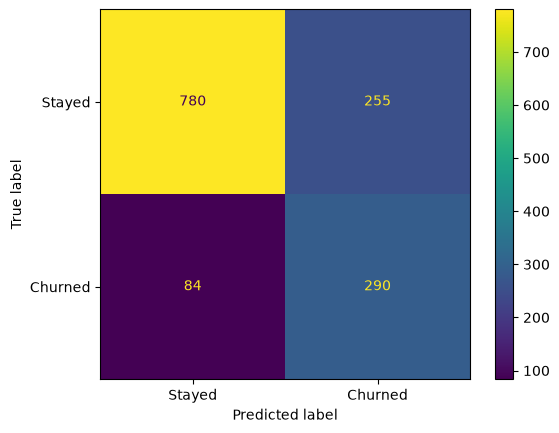

In [10]:
from sklearn.metrics import classification_report, roc_auc_score, ConfusionMatrixDisplay

final_model.fit(X_train, y_train)
test_proba = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= best_t).astype(int)

print("Test ROC-AUC:", round(roc_auc_score(y_test, test_proba), 3))
print(classification_report(y_test, test_pred, target_names=["Stayed", "Churned"]))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["Stayed", "Churned"])
plt.show()

In [12]:
import shap

prep = final_model.named_steps["prep"]
model = final_model.named_steps["model"]

def to_df(X):
    Xt = prep.transform(X)
    if hasattr(Xt, "toarray"):      # OneHotEncoder may return a sparse matrix
        Xt = Xt.toarray()
    names = [n.replace("num__", "").replace("cat__", "") for n in prep.get_feature_names_out()]
    return pd.DataFrame(Xt, columns=names)

X_train_t = to_df(X_train)
X_test_t = to_df(X_test)

if final_name == "XGBoost":
    # Tree models: no background data needed
    explainer = shap.TreeExplainer(model)
else:
    # Logistic Regression: use a linear explainer with the full training set as background
    masker = shap.maskers.Independent(X_train_t, max_samples=len(X_train_t))
    explainer = shap.LinearExplainer(model, masker)

shap_values = explainer(X_test_t)
print("Explained with:", final_name, "| SHAP values shape:", shap_values.values.shape)

Explained with: XGBoost | SHAP values shape: (1409, 51)


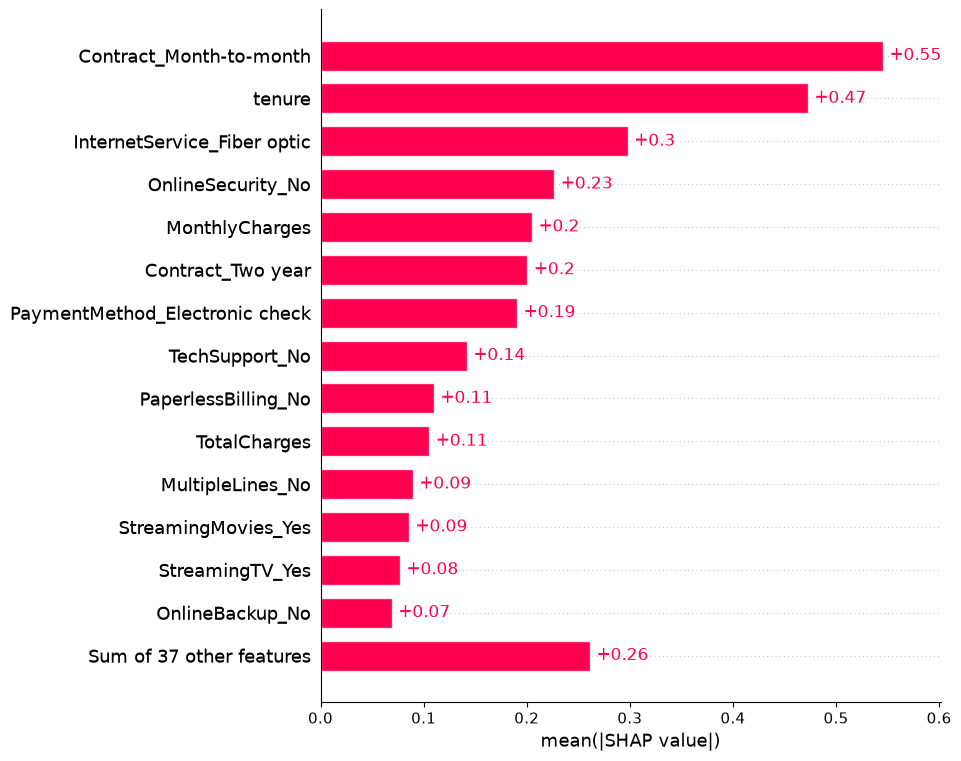

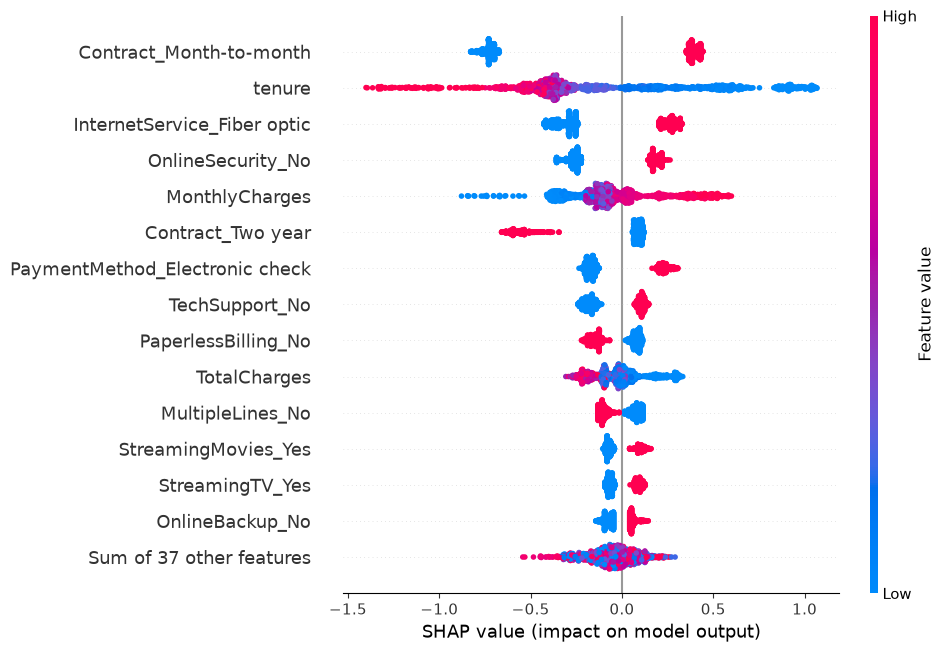

In [13]:
shap.plots.bar(shap_values, max_display=15)
shap.plots.beeswarm(shap_values, max_display=15)

Churn probability: 0.955 | Actual churn: 1


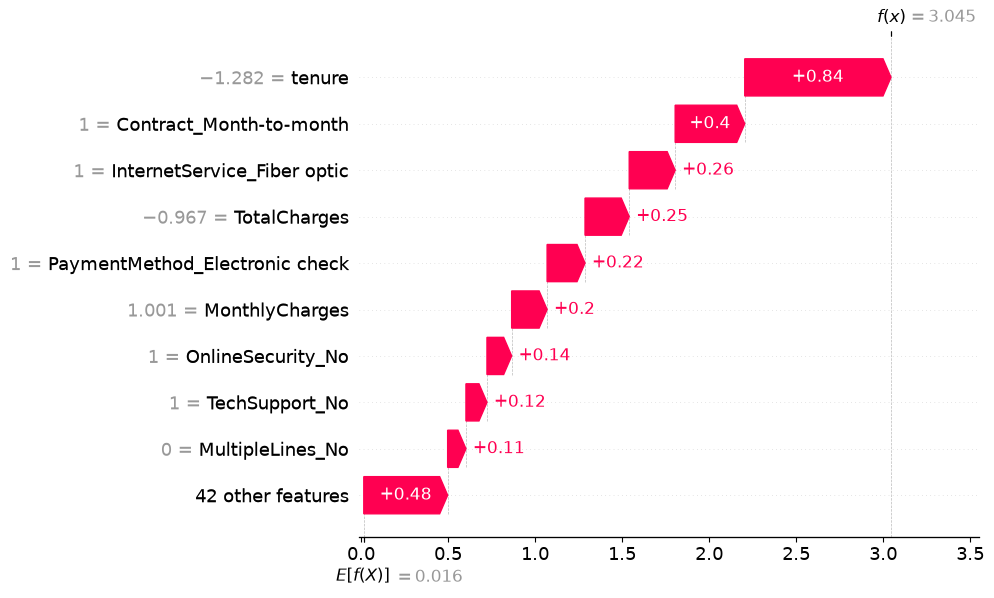

In [14]:
# Pick the test customer the model considers riskiest
idx = int(np.argmax(test_proba))
print("Churn probability:", round(test_proba[idx], 3), "| Actual churn:", int(y_test.iloc[idx]))
shap.plots.waterfall(shap_values[idx], max_display=10)

In [15]:
import joblib, json

joblib.dump(final_model, "../models/churn_model.joblib")
with open("../models/config.json", "w") as f:
    json.dump({"model": final_name, "threshold": float(best_t)}, f)

print("Saved")

Saved
